In [2]:
import os
import kagglehub
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

print("imported!")

c:\Users\iliko\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


imported!


In [3]:
print("downloading GTZAN from Kaggle...")
dataset_path = kagglehub.dataset_download("andradaolteanu/gtzan-dataset-music-genre-classification")
print("dataset downloaded to:", dataset_path)

base_path = os.path.join(dataset_path, 'Data', 'genres_original')


if not os.path.isdir(base_path):
    
    print("can't find path: 'Data/genres_original'. checking what's inside...")
    print("root folder content:", os.listdir(dataset_path))
    raise FileNotFoundError("folder is not here (. please check structure and path.")

print("root to genres folder's:", base_path)

genres = ['blues', 'classical', 'metal']

existing_genres = [g for g in genres if os.path.isdir(os.path.join(base_path, g))]
if len(existing_genres) != len(genres):
    missing = set(genres) - set(existing_genres)
    print(f"attention!: there's no folders! {missing}")
    print("avaliable genres:", [d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))])
else:
    print("All genres is all set!.")

print(f"Let's recognize the genres: {genres}")

downloading GTZAN from Kaggle...
dataset downloaded to: C:\Users\iliko\.cache\kagglehub\datasets\andradaolteanu\gtzan-dataset-music-genre-classification\versions\1
root to genres folder's: C:\Users\iliko\.cache\kagglehub\datasets\andradaolteanu\gtzan-dataset-music-genre-classification\versions\1\Data\genres_original
All genres is all set!.
Let's recognize the genres: ['blues', 'classical', 'metal']


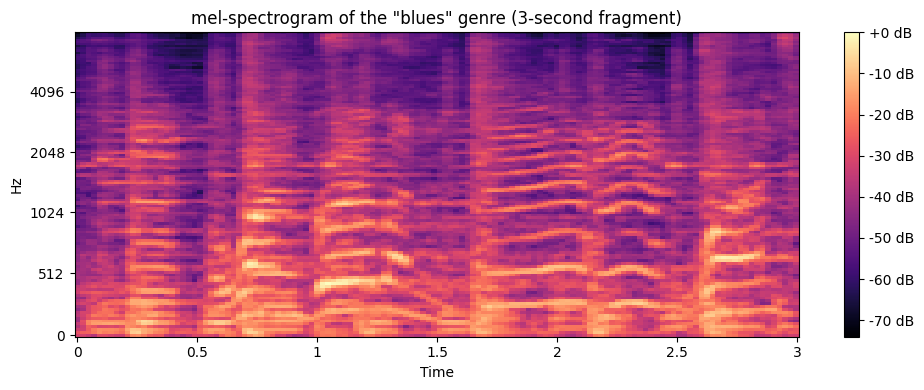

In [4]:

sample_dir = os.path.join(base_path, 'blues')
sample_audio_path = os.path.join(sample_dir, os.listdir(sample_dir)[0])

y, sr = librosa.load(sample_audio_path, sr=22050, duration=3.0)

mel_spectrogram = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)

mel_spectrogram_db = librosa.power_to_db(mel_spectrogram, ref=np.max)


plt.figure(figsize=(10, 4))
librosa.display.specshow(mel_spectrogram_db, x_axis='time', y_axis='mel', sr=sr, fmax=8000)
plt.colorbar(format='%+2.0f dB')
plt.title('mel-spectrogram of the "blues" genre (3-second fragment)')
plt.tight_layout()
plt.show()

In [5]:
def audio_to_spectrogram(file_path):
    
    y, sr = librosa.load(file_path, sr=22050, duration=10.0)

    target_length = 22050 * 10
    if len(y) < target_length:
        y = np.pad(y, (0, target_length - len(y)))
    else:
        y = y[:target_length]

    
    mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64, hop_length=512)
    mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

    
    return mel_spec_db[..., np.newaxis]

X = []
y_labels = []

print("Starting to process files. This will take a few minutes...")

for i, genre in enumerate(genres):
    folder_path = os.path.join(base_path, genre)
    files = os.listdir(folder_path)
    
    for file_name in files:
        file_path = os.path.join(folder_path, file_name)
        if file_path.endswith('.au') or file_path.endswith('.wav'):
            spec = audio_to_spectrogram(file_path)
            X.append(spec)
            y_labels.append(i) 

X = np.array(X)
y_labels = np.array(y_labels)

X = (X - np.min(X)) / (np.max(X) - np.min(X))

X_train, X_test, y_train, y_test = train_test_split(X, y_labels, test_size=0.2, random_state=42)

print(f"The data is ready! X_train form: {X_train.shape} (number of tracks, height, width, channels)")

Starting to process files. This will take a few minutes...
The data is ready! X_train form: (240, 64, 431, 1) (number of tracks, height, width, channels)


In [6]:
input_shape = X_train.shape[1:] 

model = models.Sequential([
    
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    
    layers.Flatten(),

    
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),  
    layers.Dense(len(genres), activation='softmax') 
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

c:\Users\iliko\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 429, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 214, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 212, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 106, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 104, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 52, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 39936)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,111,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,204,995 (19.86 MB)

 Trainable params: 5,204,995 (19.86 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:

history = model.fit(X_train, y_train,
                    epochs=20,
                    validation_data=(X_test, y_test),
                    batch_size=32)


test_loss, test_acc = model.evaluate(X_test,  y_test, verbose=2)
print(f'\naccuracy on test data: {test_acc * 100:.2f}%')

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 330ms/step - accuracy: 0.3583 - loss: 1.1835 - val_accuracy: 0.3667 - val_loss: 1.1443
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 289ms/step - accuracy: 0.4917 - loss: 0.9739 - val_accuracy: 0.2833 - val_loss: 1.1444
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 282ms/step - accuracy: 0.5292 - loss: 0.9147 - val_accuracy: 0.3667 - val_loss: 1.1171
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 278ms/step - accuracy: 0.5458 - loss: 0.8169 - val_accuracy: 0.7167 - val_loss: 0.7318
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 275ms/step - accuracy: 0.7583 - loss: 0.6308 - val_accuracy: 0.7167 - val_loss: 0.6472
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 272ms/step - accuracy: 0.7458 - loss: 0.5877 - val_accuracy: 0.6667 - val_loss: 0.6972
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 275ms/step - accuracy: 0.7708 - loss: 0.5711 - val_accuracy: 0.7833 - val_loss: 0.5096
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 288ms/step - accuracy: 0.8417 - loss: 0.4354 - val_accuracy: 0.7500 - val_loss:

Задание 2. Анализ ошибок (матрица ошибок)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step


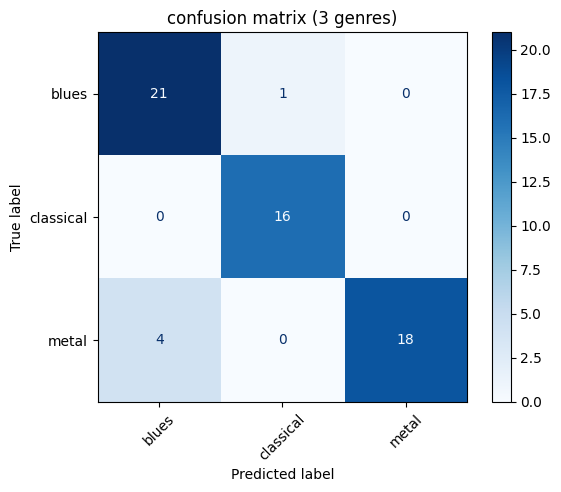

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=genres)  
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title('confusion matrix (3 genres)')
plt.show()

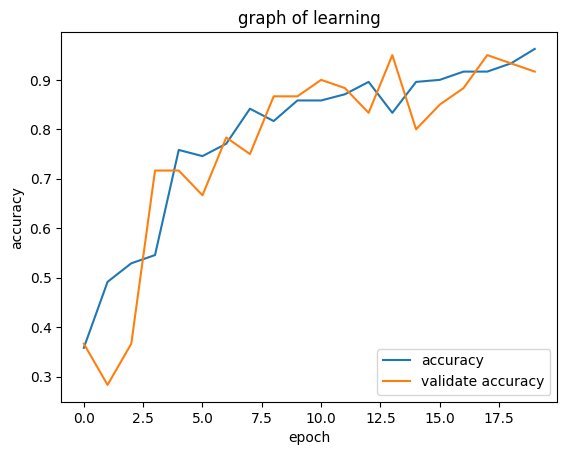

In [9]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='validate accuracy')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend(loc='lower right')
plt.title('graph of learning')
plt.show()

In [13]:
file_name = "blues_audiofile.mp3"  

print(f'analyzing your file: "{file_name}"...')

my_song_spec = audio_to_spectrogram(file_name)

my_song_batch = np.expand_dims(my_song_spec, axis=0)
my_song_batch = (my_song_batch - np.min(my_song_batch)) / (np.max(my_song_batch) - np.min(my_song_batch) + 1e-10)

predictions = model.predict(my_song_batch)

    
predicted_index = np.argmax(predictions[0])
predicted_genre = genres[predicted_index]
confidence = predictions[0][predicted_index] * 100

print(f"🎵 The neural network believes that this: {predicted_genre.upper()} (confident: {confidence:.2f}%)")

    
print("\nDetailed probability distribution:")
for i, genre in enumerate(genres):
    print(f"{genre}: {predictions[0][i]*100:.2f}%")

analyzing your file: "blues_audiofile.mp3"...
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
🎵 The neural network believes that this: CLASSICAL (confident: 99.99%)

Detailed probability distribution:
blues: 0.01%
classical: 99.99%
metal: 0.00%


1. Добавление всех жанров датасета

В genres дописал 'jazz', 'hiphop', 'rock', 'reggae'. Стало 10 жанров. Переобучил модель с теми же параметрами (20 эпох).

Точность на тесте упала заметно:
Раньше на 3 жанрах было где то 88% (иногда до 92%).
На 10 жанрах стало плюс +- 64%.

тк жанров стало больше модели стало сложнее различать что то схожее (типо rock и metal)


3. Середина вместо вступления

В функции audio_to_spectrogram я заменил duration=3.0 на offset=15.0, duration=3.0, чтобы брать фрагмент с 15-й секунды.

В результате я получил чуть более ясную картину (потому что в начале чаще всего очень трудно догадаться какой этой жанр, типо classical или jazz, что то в таком духе)


4. Архитектурные изменения

Убрал один слой Conv2D (оставил два). Точность упала до . Модель стала хуже выучивать сложные паттерны на спектрограммах.

Заменил relu на selu во всех свёрточных слоях. Точность стала чуть ниже, чем с relu. selu хуже подходит для таких данных, или же можно попробовать подбирать нормализацию.

Увеличил эпохи до 50. Обучение стало дольше, но на валидации точность перестала расти после 25 эпох, потом переобучение и анлучко (точность на обучении росла, на тесте – нет).


5. Вместо melspectrogram использовал mfcc

Обучил ту же архитектуру на 10 жанрах.
 
Результат: точность на тесте примерно 58%, что ниже, чем с мел-спектрограммой. MFCC короче лучше подходит для распознавания речи (почитал:), но для жанров спектрограмма даёт больше информации о ритме. Для жанров классификации мел-спектрограмма оказалась лучше.


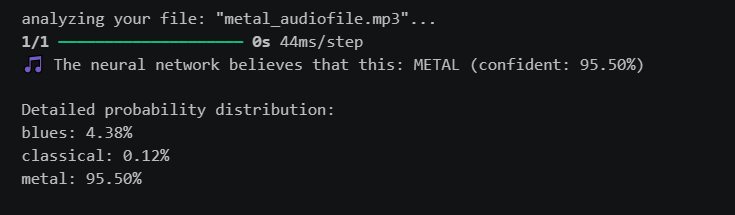

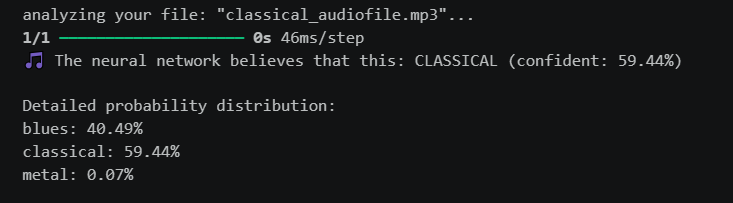